In [3]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
exercise = pd.read_csv("exercise.csv")
calories = pd.read_csv("calories.csv")
df = exercise.merge(calories, on="User_ID").drop(columns="User_ID")
print(df.shape)
df.head()

(15000, 8)


,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,female,27,154.0,58.0,10.0,81.0,39.8,35.0


In [9]:
print(df.isna().sum())
print(df.duplicated().sum())
df.describe()

Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64
1


,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453,89.539533
std,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230,62.456978
min,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000
25%,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000,35.000000
50%,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000,79.000000
75%,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000,138.000000
max,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000,314.000000


In [10]:
print(df.isna().sum())
print(df.duplicated().sum())
df.describe()

Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64
1


,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453,89.539533
std,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230,62.456978
min,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000
25%,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000,35.000000
50%,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000,79.000000
75%,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000,138.000000
max,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000,314.000000


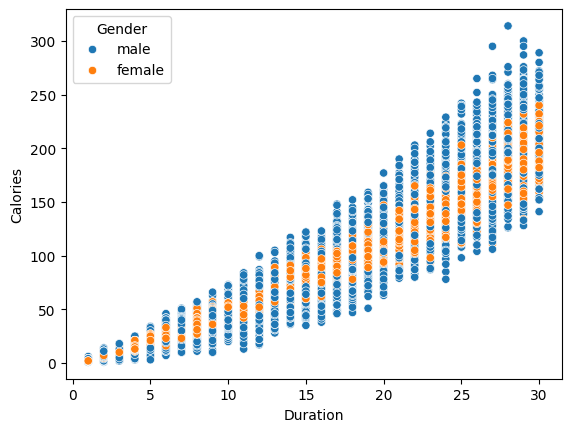

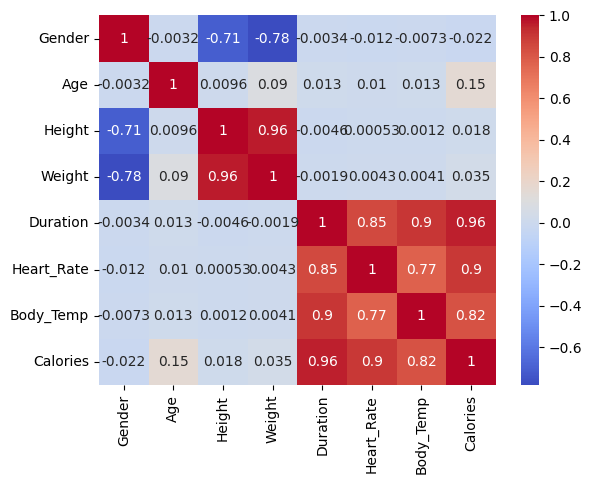

In [11]:
sns.scatterplot(data=df, x="Duration", y="Calories", hue="Gender")
plt.show()

df["Gender"] = df["Gender"].map({"male": 0, "female": 1})
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Calories")
y = df["Calories"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(12000, 7) (3000, 7)


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

lr = LinearRegression().fit(X_train[["Duration"]], y_train)
pred = lr.predict(X_test[["Duration"]])
print("Duration only → MAE:", mean_absolute_error(y_test, pred), "R2:", r2_score(y_test, pred))

Duration only → MAE: 13.613490784700517 R2: 0.9145047527249381


In [17]:
lr_all = LinearRegression().fit(X_train, y_train)
pred = lr_all.predict(X_test)
print("All features → MAE:", mean_absolute_error(y_test, pred), "R2:", r2_score(y_test, pred))

All features → MAE: 8.44151355384972 R2: 0.9672937151257295


In [18]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)
print("RandomForest → MAE:", mean_absolute_error(y_test, pred), "R2:", r2_score(y_test, pred))

RandomForest → MAE: 1.686655 R2: 0.9982633448116194
